# 实验01：先读懂数据，再理解基因筛选

本 notebook 读取已经完成的真实实验结果，不重复训练。按顺序运行。重点是理解样本、矩阵、分组、效应量和外部复核。详细方法见 protocol.md。

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, Image
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'datasets').is_dir() and (p / 'experiments').is_dir())
OUT = ROOT / 'outputs/01_fibroblast_screening'

## 1. 每个样本到底是什么？

GSM 是样本编号，day 是采样时间，replicate 是作者重复编号。FB 是成纤维细胞。每个发现文库池化三只小鼠，但统计单位仍然是一个文库。

In [2]:
samples = pd.read_csv(ROOT / 'datasets/GSE252027/metadata/samples_FB.csv').set_index('gsm')
display(samples[['day', 'replicate', 'cell_type_abbreviation', 'pooled_mice_per_library']])
display(samples.groupby('day').size().rename('提交文库数'))

,day,replicate,cell_type_abbreviation,pooled_mice_per_library
gsm,,,,
GSM7992326,0,1,FB,3
GSM7992327,0,2,FB,3
GSM7992328,0,3,FB,3
GSM7992329,0,4,FB,3
GSM7992330,1,1,FB,3
GSM7992331,1,2,FB,3
GSM7992332,1,3,FB,3
GSM7992333,1,4,FB,3
GSM7992334,3,1,FB,3


day
0     4
1     4
3     4
7     4
14    4
28    4
Name: 提交文库数, dtype: int64

## 2. 表达矩阵的行和列

这里每一行是一个基因，每一列是一个文库。TPM 是相对丰度，用于阅读和画图；主要差异检验使用长度缩放后的计数尺度。

In [3]:
tpm = pd.read_csv(OUT / 'FB_TPM.tsv.gz', sep='\t', index_col=0)
print('基因数、文库数：', tpm.shape)
assert list(tpm.columns) == list(samples.index)
display(tpm.iloc[:6, :6])

基因数、文库数： (51029, 24)


,GSM7992326,GSM7992327,GSM7992328,GSM7992329,GSM7992330,GSM7992331
Name,,,,,,
ENSMUSG00000089596,0.000000,0.000000,0.0,0.000000,0.0,0.000000
ENSMUSG00000098869,0.000000,0.000000,0.0,0.000000,0.0,0.000000
ENSMUSG00000098974,0.000000,0.000000,0.0,0.000000,0.0,0.000000
ENSMUSG00000099143,0.000000,0.000000,0.0,0.000000,0.0,0.000000
ENSMUSG00000088338,0.209089,0.132914,0.0,0.123952,0.0,0.508703
ENSMUSG00000087801,0.000000,0.000000,0.0,0.000000,0.0,0.000000


## 3. 把样本表与矩阵连接起来

`isin([0, 7])` 产生布尔条件，选择 D0 或 D7 的样本；拿到 GSM 后，再选择表达矩阵的对应列。这一步必须按 ID 对齐，不能只凭列的位置。

In [4]:
selected_ids = samples.index[samples['day'].isin([0, 7])]
experiment_samples = samples.loc[selected_ids, ['day', 'replicate']]
display(experiment_samples)
assert experiment_samples.groupby('day').size().to_dict() == {0: 4, 7: 4}
cthrc1_id = 'ENSMUSG00000054196'
display(tpm.loc[[cthrc1_id], selected_ids].round(3))

,day,replicate
gsm,,
GSM7992326,0,1
GSM7992327,0,2
GSM7992328,0,3
GSM7992329,0,4
GSM7992338,7,1
GSM7992339,7,2
GSM7992340,7,3
GSM7992341,7,4


,GSM7992326,GSM7992327,GSM7992328,GSM7992329,GSM7992338,GSM7992339,GSM7992340,GSM7992341
Name,,,,,,,,
ENSMUSG00000054196,0.651,0.574,0.504,0.494,160.87,63.499,54.709,115.817


## 4. 从这一行能知道什么，不能知道什么？

Cthrc1 在 D7 各文库中都高于 D0，这是直观表达证据。TPM 不处理所有统计问题，不能仅据此判定因果或药物靶点。下面读取模型结果。

In [5]:
evidence = pd.read_csv(OUT / 'all_evidence.tsv', sep='\t', index_col=0)
columns = ['symbol', 'log2FoldChange', 'padj', 'validation_log2FC', 'validation_padj', 'same_direction']
display(evidence.loc[[cthrc1_id], columns])
print('发现模型的倍数点估计：', round(2 ** evidence.loc[cthrc1_id, 'log2FoldChange'], 1))

,symbol,log2FoldChange,padj,validation_log2FC,validation_padj,same_direction
Name,,,,,,
ENSMUSG00000054196,Cthrc1,7.832189,2.677949e-139,9.050032,0.030141,True


发现模型的倍数点估计： 227.9


## 5. 亲自写出筛选条件

发现队列要求 padj<0.05 且绝对 log2FC≥1；外部队列要求 padj<0.05、绝对 log2 表达差≥0.5，且方向一致。下面的布尔运算每行计算一次，最后按 True 选行。阈值在看结果前已写入设计。

In [6]:
discovery_pass = (evidence['padj'] < 0.05) & (evidence['log2FoldChange'].abs() >= 1)
external_pass = (evidence['validation_padj'] < 0.05) & (evidence['validation_log2FC'].abs() >= 0.5)
same_direction = evidence['log2FoldChange'] * evidence['validation_log2FC'] > 0
selected = evidence.loc[discovery_pass & external_pass & same_direction]
print('发现候选：', int(discovery_pass.sum()))
print('跨队列支持：', len(selected))
assert set(selected.index) == set(evidence.index[evidence.cross_cohort_supported])
display(selected[columns])

发现候选： 1501
跨队列支持： 4


,symbol,log2FoldChange,padj,validation_log2FC,validation_padj,same_direction
Name,,,,,,
ENSMUSG00000058135,Gstm1,-1.496426,6.767980e-08,-3.778440,0.030141,True
ENSMUSG00000054196,Cthrc1,7.832189,2.677949e-139,9.050032,0.030141,True
ENSMUSG00000002020,Ltbp2,3.640649,1.428602e-08,6.407834,0.030141,True
ENSMUSG00000007888,Crlf1,1.858446,5.881012e-03,3.922030,0.030141,True


## 6. 为什么熟悉的名字没入选？

Col1a1、Col3a1、Postn 的方向同样可以一致，但外部校正结果没有通过本次门槛。未通过不等于没有生物学作用；它表示本轮证据不足以按这套规则入选。不要看结果后改规则以获得喜欢的基因。

In [7]:
display(evidence.loc[evidence.symbol.isin(['Col1a1', 'Col3a1', 'Postn']), columns + ['discovery_pass', 'cross_cohort_supported']])

,symbol,log2FoldChange,padj,validation_log2FC,validation_padj,same_direction,discovery_pass,cross_cohort_supported
Name,,,,,,,,
ENSMUSG00000001506,Col1a1,2.406142,1.390780e-35,2.297123,0.080018,True,True,False
ENSMUSG00000026043,Col3a1,2.419319,1.885727e-39,2.337717,0.122607,True,True,False
ENSMUSG00000027750,Postn,4.135361,4.810924e-41,2.606320,0.193441,True,True,False


## 7. 看每个点，而不是只看折线

每个点是一个独立提交的样本/文库。黑线连接组均值，不是同一只动物的轨迹。左右队列表达尺度不同；时间点等距绘制，不代表天数间隔相等。全部 D3 文库保留在描述图中，主要检验没有使用 D3。

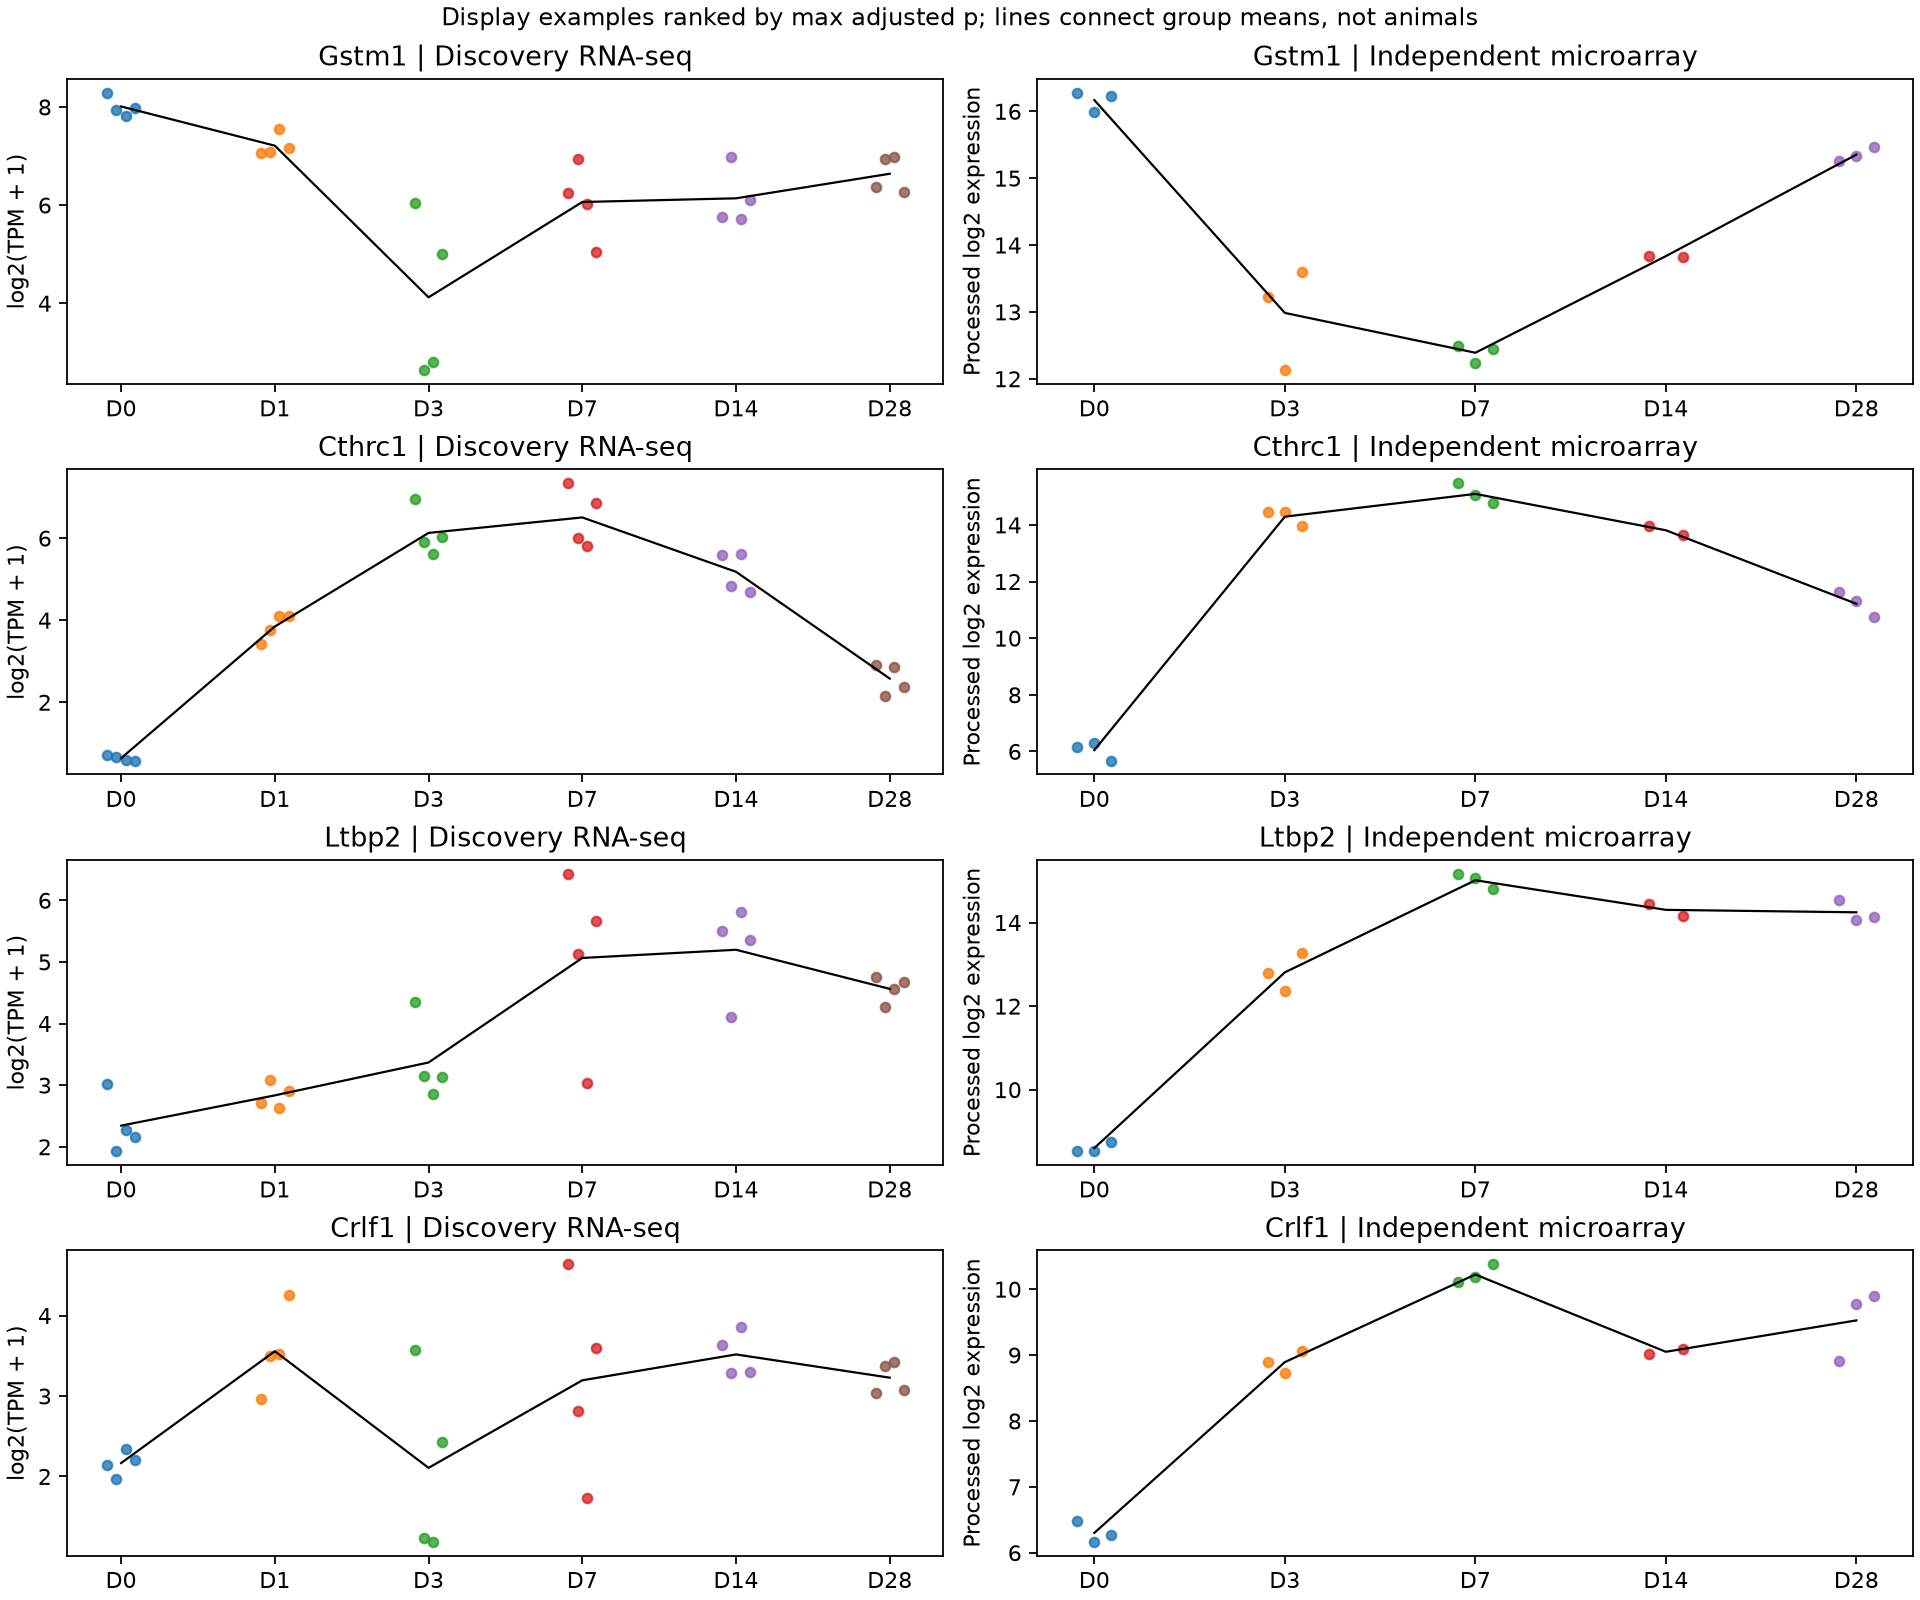

In [8]:
display(Image(filename=str(OUT / '02_candidate_time_profiles.png'), width=1000))

## 8. 用删除一个文库检查方向是否依赖单个值

只做描述性敏感性检查：删除一个 D0 或 D7 文库，重新计算平均 log2(TPM+1) 差。它不是重新拟合 DESeq2，也没有新的显著性检验。

In [9]:
rows = []
for gid, record in selected.iterrows():
    case = np.log2(tpm.loc[gid, samples.index[samples.day == 7]].to_numpy() + 1)
    control = np.log2(tpm.loc[gid, samples.index[samples.day == 0]].to_numpy() + 1)
    effects = [np.delete(case, i).mean() - control.mean() for i in range(len(case))]
    effects += [case.mean() - np.delete(control, i).mean() for i in range(len(control))]
    rows.append({'gene': record.symbol, '最小均值差': min(effects), '最大均值差': max(effects), '方向始终一致': all(np.sign(v) == np.sign(record.log2FoldChange) for v in effects)})
display(pd.DataFrame(rows))

,gene,最小均值差,最大均值差,方向始终一致
0,Gstm1,-2.239108,-1.609090,True
1,Cthrc1,5.589829,6.102776,True
2,Ltbp2,2.265685,3.399442,True
3,Crlf1,0.548318,1.517249,True


## 第一课的自检

1. 51,029×24 中，哪一维是基因？哪一维是文库？
2. 为什么每文库三只小鼠不能把 4 个文库拆成 12 个统计样本？
3. `padj` 与 `log2FoldChange` 各回答什么问题？
4. 为什么不能把芯片值直接送进 RNA-seq 计数模型？
5. 为什么找到已有研究的 Cthrc1 仍然有用，却还不是新颖选题？

下一步逐行追踪 experiments/01_fibroblast_screening/run.py 中 length_scaled_counts、discovery 和 validation 的输入、形状、返回值与输出文件。当前四个候选只作为探索性结果。